# **1️⃣Data Loading & Validation**

**Kaggle Setup**

In [20]:
!pip install -q kaggle

In [21]:
from google.colab import files
import os
import shutil

uploaded = files.upload()

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.move(
    '/content/kaggle.json',
    '/root/.kaggle/kaggle.json'
)

os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("Kaggle API configured successfully!")

Saving kaggle.json to kaggle.json
Kaggle API configured successfully!


In [22]:
!kaggle --version

Kaggle CLI 2.0.2


In [23]:
!kaggle datasets download -d ealaxi/paysim1 -p /content

Dataset URL: https://www.kaggle.com/datasets/ealaxi/paysim1
License(s): CC-BY-SA-4.0
paysim1.zip: Skipping, found more recently modified local copy (use --force to force download)


In [24]:
!unzip -o /content/paysim1.zip -d /content/paysim_data

Archive:  /content/paysim1.zip
  inflating: /content/paysim_data/PS_20174392719_1491204439457_log.csv  


In [25]:
import pandas as pd

file_path = '/content/paysim_data/PS_20174392719_1491204439457_log.csv'

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset Loaded Successfully!
Dataset Shape: (6362620, 11)

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


**Cell 1 — Import Libraries**

In [26]:
import os
import gc
import warnings
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


**Cell 2 — Load Dataset**

In [27]:
if 'df' not in globals():

    df = pd.read_csv('/content/paysim.csv')

print("Dataset Loaded Successfully!")

print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (6362620, 11)


In [28]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


**Cell 3 — Dataset Information**

In [29]:
print("Dataset Information:")

df.info()

print("\nMissing Values:")

display(
    df.isnull().sum().sort_values(ascending=False)
)

print("\nDuplicate Rows:")

print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB

Missing Values:


,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0



Duplicate Rows:
0


**Cell 4 — Target Distribution**

Target Distribution:


,count
isFraud,
0,6354407
1,8213



Target Percentages:


,proportion
isFraud,
0,99.870918
1,0.129082


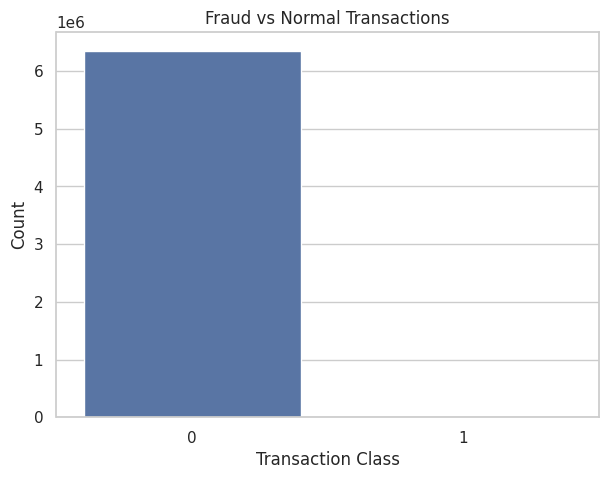

In [30]:
print("Target Distribution:")

target_counts = df['isFraud'].value_counts()

display(target_counts)

print("\nTarget Percentages:")

display(
    df['isFraud'].value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='isFraud'
)

plt.title('Fraud vs Normal Transactions')
plt.xlabel('Transaction Class')
plt.ylabel('Count')

plt.show()

**Cell 5 — Transaction Type Analysis**

Transaction Type Distribution:


,count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432



Fraud by Transaction Type:


isFraud,0,1,All
type,,,
CASH_IN,1399284,0,1399284
CASH_OUT,2233384,4116,2237500
DEBIT,41432,0,41432
PAYMENT,2151495,0,2151495
TRANSFER,528812,4097,532909
All,6354407,8213,6362620


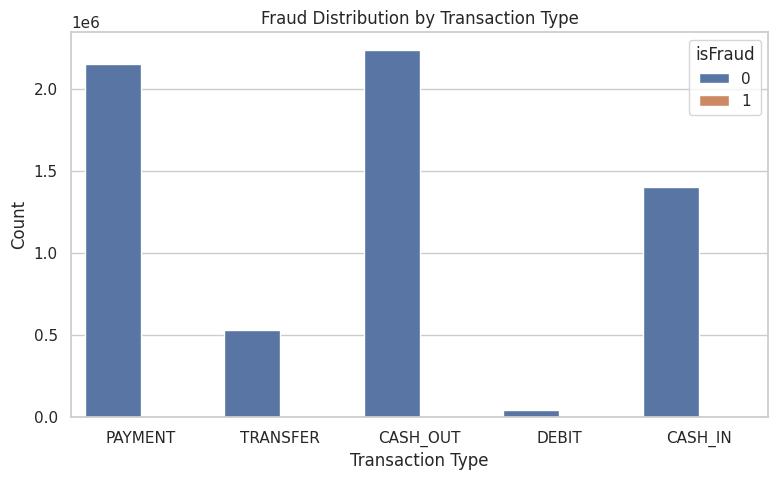

In [31]:
print("Transaction Type Distribution:")

display(
    df['type'].value_counts()
)

print("\nFraud by Transaction Type:")

fraud_by_type = pd.crosstab(
    df['type'],
    df['isFraud'],
    margins=True
)

display(fraud_by_type)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='type',
    hue='isFraud'
)

plt.title('Fraud Distribution by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Count')

plt.show()

**Cell 6 — Numerical Features Analysis**

In [32]:
numeric_features = [
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

print("Numerical Features Statistics:")

display(
    df[numeric_features].describe().T
)

Numerical Features Statistics:


,count,mean,std,min,25%,50%,75%,max
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08


**Cell 7 — isFlaggedFraud Analysis**

In [33]:
print("isFlaggedFraud vs isFraud:")

flagged_analysis = pd.crosstab(
    df['isFlaggedFraud'],
    df['isFraud'],
    margins=True
)

display(flagged_analysis)

isFlaggedFraud vs isFraud:


isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


**Cell 8 — Transaction Amount Distribution**

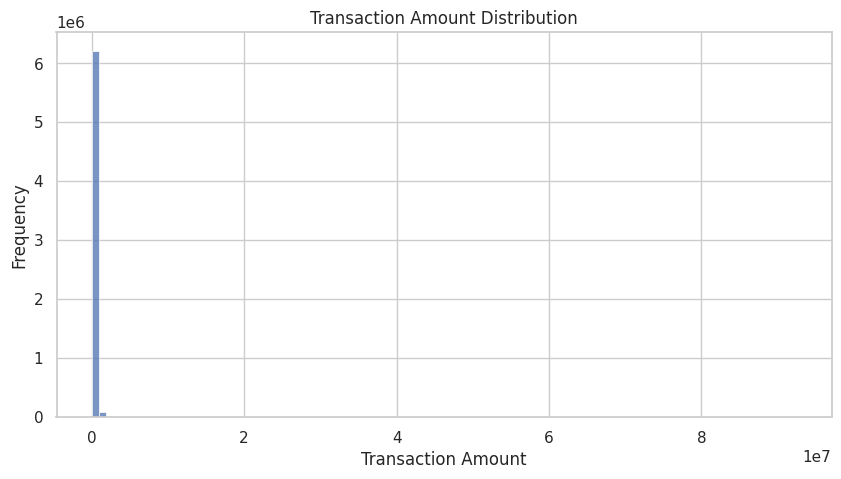

In [34]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='amount',
    bins=100
)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

# **2️⃣Data Preprocessing**

**Cell 9 — Create a Working Copy**

In [35]:
data = df.copy()

print("Working Dataset Created!")

print("Shape:", data.shape)

Working Dataset Created!
Shape: (6362620, 11)


**Cell 10 — Handle Missing Values**

In [36]:
missing_values = data.isnull().sum().sum()

print("Total Missing Values:", missing_values)

if missing_values > 0:

    print("Handling missing values...")

    for col in data.select_dtypes(include=np.number).columns:

        data[col] = data[col].fillna(data[col].median())

    for col in data.select_dtypes(include='object').columns:

        data[col] = data[col].fillna('Unknown')

else:

    print("No missing values found!")

Total Missing Values: 0
No missing values found!


# **3️⃣Feature Engineering**

**Cell 11 — Create New Features**

In [37]:
data['balance_error_orig'] = (
    data['oldbalanceOrg']
    - data['amount']
    - data['newbalanceOrig']
)

data['balance_error_dest'] = (
    data['oldbalanceDest']
    + data['amount']
    - data['newbalanceDest']
)

data['orig_balance_change'] = (
    data['oldbalanceOrg']
    - data['newbalanceOrig']
)

data['dest_balance_change'] = (
    data['newbalanceDest']
    - data['oldbalanceDest']
)

data['hour'] = data['step'] % 24

data['day'] = data['step'] // 24

print("Feature Engineering Completed!")

display(data.head())

Feature Engineering Completed!


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balance_error_orig,balance_error_dest,orig_balance_change,dest_balance_change,hour,day
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,0.0,9839.64,9839.64,0.0,1,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,0.0,1864.28,1864.28,0.0,1,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,0.0,181.00,181.00,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,0.0,21363.00,181.00,-21182.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,0.0,11668.14,11668.14,0.0,1,0


**Cell 12 — Drop Unnecessary Columns**

In [39]:
drop_columns = [
    'nameOrig',
    'nameDest',
    'isFlaggedFraud',
    'TransactionID'
]

data = data.drop(
    columns=drop_columns,
    errors='ignore'
)

print("Unnecessary Columns Removed!")

print("Remaining Columns:", len(data.columns))

Unnecessary Columns Removed!
Remaining Columns: 14


**Cell 13 — Encode Categorical Features**

In [40]:
data = pd.get_dummies(
    data,
    columns=['type'],
    dtype=int
)

print("Categorical Encoding Completed!")

display(data.head())

Categorical Encoding Completed!


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balance_error_orig,balance_error_dest,orig_balance_change,dest_balance_change,hour,day,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,160296.36,0.0,0.0,0,0.0,9839.64,9839.64,0.0,1,0,0,0,0,1,0
1,1,1864.28,21249.0,19384.72,0.0,0.0,0,0.0,1864.28,1864.28,0.0,1,0,0,0,0,1,0
2,1,181.00,181.0,0.00,0.0,0.0,1,0.0,181.00,181.00,0.0,1,0,0,0,0,0,1
3,1,181.00,181.0,0.00,21182.0,0.0,1,0.0,21363.00,181.00,-21182.0,1,0,0,1,0,0,0
4,1,11668.14,41554.0,29885.86,0.0,0.0,0,0.0,11668.14,11668.14,0.0,1,0,0,0,0,1,0


# **4️⃣Split Dataset**

**Cell 14 — Separate Features and Target**

In [41]:
X = data.drop(columns=['isFraud'])

y = data['isFraud']

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (6362620, 17)
Target Shape: (6362620,)


**Cell 15 — Train Test Split**

In [42]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("Training Shape:", X_train.shape)

print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")

display(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")

display(y_test.value_counts(normalize=True) * 100)

Training Shape: (5090096, 17)
Testing Shape: (1272524, 17)

Training Target Distribution:


,proportion
isFraud,
0,99.870926
1,0.129074



Testing Target Distribution:


,proportion
isFraud,
0,99.870887
1,0.129113


#**5️⃣Handle Class Imbalance**

**Cell 16 — Undersampling**

In [43]:
train_data = X_train.copy()

train_data['isFraud'] = y_train

fraud_data = train_data[
    train_data['isFraud'] == 1
]

normal_data = train_data[
    train_data['isFraud'] == 0
]

fraud_count = len(fraud_data)

normal_sample = normal_data.sample(
    n=min(len(normal_data), fraud_count * 20),
    random_state=42
)

balanced_train = pd.concat(
    [fraud_data, normal_sample],
    axis=0
)

balanced_train = balanced_train.sample(
    frac=1,
    random_state=42
)

X_train_balanced = balanced_train.drop(
    columns=['isFraud']
)

y_train_balanced = balanced_train['isFraud']

print("Original Training Shape:", X_train.shape)

print("Balanced Training Shape:", X_train_balanced.shape)

print("\nBalanced Target Distribution:")

display(y_train_balanced.value_counts())

Original Training Shape: (5090096, 17)
Balanced Training Shape: (137970, 17)

Balanced Target Distribution:


,count
isFraud,
0,131400
1,6570


# **6️⃣Model Training**

**Cell 17 — Install XGBoost**

In [44]:
!pip -q install xgboost

**Cell 18 — Train Random Forest**

In [45]:
rf_model = RandomForestClassifier(

    n_estimators=150,

    max_depth=20,

    min_samples_split=5,

    min_samples_leaf=2,

    class_weight='balanced_subsample',

    random_state=42,

    n_jobs=-1
)

print("Training Random Forest...")

rf_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("Random Forest Training Completed!")

Training Random Forest...
Random Forest Training Completed!


**Cell 19 — Train XGBoost**

In [46]:
from xgboost import XGBClassifier

negative_count = (y_train_balanced == 0).sum()

positive_count = (y_train_balanced == 1).sum()

scale_weight = negative_count / positive_count

xgb_model = XGBClassifier(

    n_estimators=200,

    max_depth=6,

    learning_rate=0.1,

    subsample=0.8,

    colsample_bytree=0.8,

    scale_pos_weight=scale_weight,

    eval_metric='logloss',

    tree_method='hist',

    random_state=42,

    n_jobs=-1
)

print("Training XGBoost...")

xgb_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("XGBoost Training Completed!")

Training XGBoost...
XGBoost Training Completed!


# **7️⃣Model Evaluation**

**Cell 20 — Evaluation Function**

In [47]:
def evaluate_model(model, X_test, y_test, model_name):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    results = {

        'Model': model_name,

        'Accuracy': accuracy_score(
            y_test,
            predictions
        ),

        'Precision': precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        'F1 Score': f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        'ROC-AUC': roc_auc_score(
            y_test,
            probabilities
        ),

        'PR-AUC': average_precision_score(
            y_test,
            probabilities
        )
    }

    print(f"\n{model_name} Classification Report:")

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )

    return results

**Cell 21 — Evaluate Random Forest**

In [48]:
rf_results = evaluate_model(

    rf_model,

    X_test,

    y_test,

    "Random Forest"
)

display(
    pd.DataFrame([rf_results])
)


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      1.00      1.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      1.00      1.00   1272524
weighted avg       1.00      1.00      1.00   1272524



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,0.999992,0.996353,0.997565,0.996959,0.999362,0.998628


**Cell 22 — Evaluate XGBoost**

In [49]:
xgb_results = evaluate_model(

    xgb_model,

    X_test,

    y_test,

    "XGBoost"
)

display(
    pd.DataFrame([xgb_results])
)


XGBoost Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.93      1.00      0.96      1643

    accuracy                           1.00   1272524
   macro avg       0.97      1.00      0.98   1272524
weighted avg       1.00      1.00      1.00   1272524



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,XGBoost,0.999905,0.932878,0.998174,0.964422,0.999807,0.998652


**Cell 23 — Compare Models**

In [50]:
comparison = pd.DataFrame([

    rf_results,

    xgb_results

])

comparison = comparison.set_index('Model')

display(
    comparison.style.highlight_max(
        axis=0,
        color='lightgreen'
    )
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.999992,0.996353,0.997565,0.996959,0.999362,0.998628
XGBoost,0.999905,0.932878,0.998174,0.964422,0.999807,0.998652


**Cell 24 — Confusion Matrix**

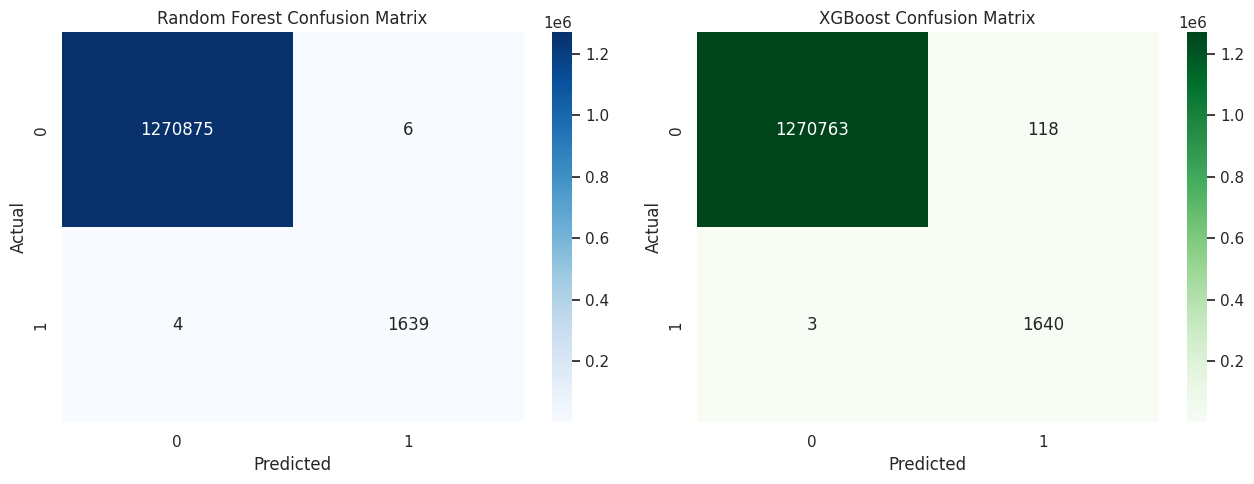

In [51]:
rf_predictions = rf_model.predict(X_test)

xgb_predictions = xgb_model.predict(X_test)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

sns.heatmap(

    confusion_matrix(y_test, rf_predictions),

    annot=True,

    fmt='d',

    cmap='Blues',

    ax=axes[0]
)

axes[0].set_title('Random Forest Confusion Matrix')

axes[0].set_xlabel('Predicted')

axes[0].set_ylabel('Actual')


sns.heatmap(

    confusion_matrix(y_test, xgb_predictions),

    annot=True,

    fmt='d',

    cmap='Greens',

    ax=axes[1]
)

axes[1].set_title('XGBoost Confusion Matrix')

axes[1].set_xlabel('Predicted')

axes[1].set_ylabel('Actual')

plt.tight_layout()

plt.show()

# **8️⃣Feature Importance**

**Cell 25 — Random Forest Feature Importance**

,Feature,Importance
6,balance_error_orig,0.324641
8,orig_balance_change,0.232478
3,newbalanceOrig,0.107679
2,oldbalanceOrg,0.086778
1,amount,0.057528
15,type_PAYMENT,0.049785
16,type_TRANSFER,0.028720
0,step,0.019574
9,dest_balance_change,0.017955
7,balance_error_dest,0.014364


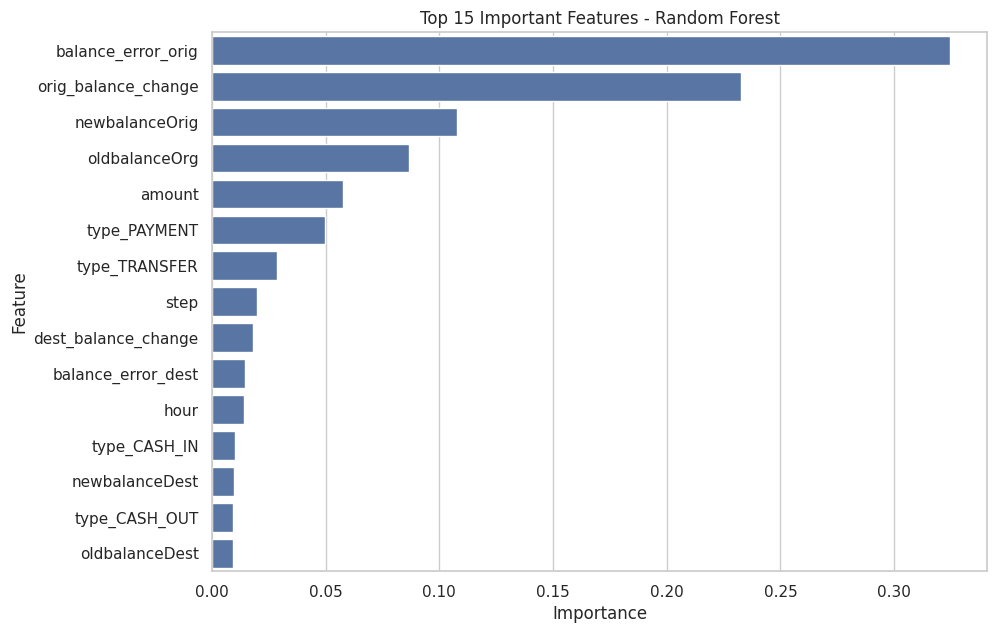

In [52]:
feature_importance = pd.DataFrame({

    'Feature': X_train_balanced.columns,

    'Importance': rf_model.feature_importances_

})

feature_importance = feature_importance.sort_values(

    by='Importance',

    ascending=False

)

display(feature_importance.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(

    data=feature_importance.head(15),

    x='Importance',

    y='Feature'

)

plt.title('Top 15 Important Features - Random Forest')

plt.show()

# **9️⃣Save Models**

**Cell 26 — Select Best Model and Save**

In [53]:
if rf_results['PR-AUC'] >= xgb_results['PR-AUC']:

    best_model = rf_model

    best_model_name = 'Random Forest'

else:

    best_model = xgb_model

    best_model_name = 'XGBoost'


print("Selected Model:", best_model_name)

model_package = {

    'model': best_model,

    'model_name': best_model_name,

    'feature_columns': list(X_train_balanced.columns)

}

joblib.dump(

    model_package,

    '/content/fraud_detection_model.pkl'

)

print("Model Saved Successfully!")

Selected Model: XGBoost
Model Saved Successfully!


# **1️⃣0️⃣Test a New Transaction**

**Cell 27 — Predict New Transaction**

In [54]:
sample_transaction = X_test.iloc[[0]]

prediction = best_model.predict(
    sample_transaction
)[0]

probability = best_model.predict_proba(
    sample_transaction
)[0][1]

print("Fraud Detection Result:")

if prediction == 1:

    print("WARNING: Potential Fraud Transaction!")

else:

    print("Normal Transaction")

print(f"Fraud Probability: {probability:.4f}")

Fraud Detection Result:
Normal Transaction
Fraud Probability: 0.0000


# **1️⃣1️⃣Prepare Flask API**

**Cell 28 — Install Flask**

In [55]:
!pip -q install flask

**Cell 29 — Create Flask Application**

In [56]:
from flask import Flask, request, jsonify

app = Flask(__name__)

loaded_package = joblib.load(
    '/content/fraud_detection_model.pkl'
)

api_model = loaded_package['model']

feature_columns = loaded_package['feature_columns']


@app.route('/predict', methods=['POST'])

def predict():

    try:

        input_data = request.get_json()

        input_df = pd.DataFrame([input_data])

        input_df = pd.get_dummies(
            input_df,
            columns=['type'],
            dtype=int
        )

        input_df = input_df.reindex(
            columns=feature_columns,
            fill_value=0
        )

        prediction = int(
            api_model.predict(input_df)[0]
        )

        probability = float(
            api_model.predict_proba(input_df)[0][1]
        )

        return jsonify({

            'prediction': prediction,

            'result': (
                'Fraud'
                if prediction == 1
                else 'Normal'
            ),

            'fraud_probability': probability

        })

    except Exception as e:

        return jsonify({

            'error': str(e)

        }), 400